# Landmark Recognition Using SIFT

## Task 1: Landmark image database

In [ ]:
import os, glob, time, shutil, io
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

landmarks = {
    "Eiffel Tower": "Eiffel Tower",
    "Taj Mahal": "Taj Mahal",
    "Great Wall of China": "Great Wall of China",
    "Statue of Liberty": "Statue of Liberty",
    "Colosseum": "Colosseum Rome",
}
unknown_label = "Unknown (not in database)"
unknown_query = "Great Pyramid of Giza"

images_per_class = 16
n_ref = 8
db_root = "landmark_db"
unknown_root = "unknown_images"

api = "https://commons.wikimedia.org/w/api.php"
headers = {"User-Agent": "SIFT-landmark-lab/1.0 (student project)"}
skip_words = ["map", "logo", "diagram", "flag", "stamp", "poster", "painting", "drawing", "plan",
              "coat", "icon", "sketch", "postcard", "model", "lego", "cake", "replica", "engraving"]

def folder_of(name):
    return os.path.join(db_root, name.replace(" ", "_"))

def load_img(path, max_side=800):
    img = cv2.imread(path)
    if img is None:
        return None
    h, w = img.shape[:2]
    if min(h, w) < 200:
        return None
    scale = max_side / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)))
    return img

def search_images(query, limit=50):
    params = {
        "action": "query", "format": "json", "generator": "search",
        "gsrsearch": query, "gsrnamespace": 6, "gsrlimit": limit,
        "prop": "imageinfo", "iiprop": "url|mime|size", "iiurlwidth": 1000,
    }
    r = requests.get(api, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    pages = r.json().get("query", {}).get("pages", {})
    found = []
    for p in sorted(pages.values(), key=lambda x: x.get("index", 0)):
        info = p.get("imageinfo", [{}])[0]
        title = p.get("title", "").lower()
        if info.get("mime") != "image/jpeg":
            continue
        if info.get("width", 0) < 600 or info.get("height", 0) < 400:
            continue
        if any(w in title for w in skip_words):
            continue
        found.append(info.get("thumburl") or info.get("url"))
    return found

def download(url, path):
    for attempt in range(3):
        try:
            r = requests.get(url, headers=headers, timeout=30)
            if r.status_code == 200:
                with open(path, "wb") as f:
                    f.write(r.content)
                return True
        except requests.RequestException:
            pass
        time.sleep(2 * (attempt + 1))
    return False

def fetch_class(query, folder, n):
    os.makedirs(folder, exist_ok=True)
    have = len(glob.glob(folder + "/*.jpg"))
    if have >= n:
        return
    try:
        urls = search_images(query)
    except Exception as e:
        print("search failed for", query, "-", e)
        return
    for url in urls:
        if have >= n:
            break
        path = os.path.join(folder, "img_%02d.jpg" % have)
        if download(url, path) and load_img(path) is not None:
            have += 1
        elif os.path.exists(path):
            os.remove(path)
        time.sleep(0.3)

for name, query in landmarks.items():
    fetch_class(query, folder_of(name), images_per_class)
    print(name, "- images downloaded:", len(glob.glob(folder_of(name) + "/*.jpg")))

fetch_class(unknown_query, unknown_root, 6)
print("unknown landmark images downloaded:", len(glob.glob(unknown_root + "/*.jpg")))

Eiffel Tower - images downloaded: 16
Taj Mahal - images downloaded: 16
Great Wall of China - images downloaded: 16
Statue of Liberty - images downloaded: 16
Colosseum - images downloaded: 16
unknown landmark images downloaded: 6


If a landmark ends up with too few images, run the cell below, upload a zip with folders named like landmark_db/Taj_Mahal/ and run the loading cell again.

In [ ]:
from google.colab import files
import zipfile

uploaded = files.upload()
for fname in uploaded:
    if fname.endswith(".zip"):
        with zipfile.ZipFile(fname) as z:
            z.extractall(".")
print("done")

done


In [ ]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

references = {}
held_out = {}
for name in landmarks:
    loaded = []
    for f in sorted(glob.glob(folder_of(name) + "/*")):
        im = load_img(f)
        if im is not None:
            loaded.append((f, im))
    references[name] = loaded[:n_ref]
    held_out[name] = loaded[n_ref:]
    print(name, "- reference images:", len(references[name]), "| held out for testing:", len(held_out[name]))
    if len(references[name]) < 3 or len(held_out[name]) < 2:
        raise RuntimeError("Not enough images for " + name + ". Put at least 10 jpg photos in " + folder_of(name) + " and run this cell again.")

unknown_imgs = []
for f in sorted(glob.glob(unknown_root + "/*")):
    im = load_img(f)
    if im is not None:
        unknown_imgs.append(im)
print("unknown landmark images:", len(unknown_imgs))
if len(unknown_imgs) < 1:
    raise RuntimeError("No unknown landmark images found in " + unknown_root + ". Put 2 or more jpg photos of a landmark that is not in the database there.")

Eiffel Tower - reference images: 8 | held out for testing: 8
Taj Mahal - reference images: 8 | held out for testing: 8
Great Wall of China - reference images: 8 | held out for testing: 8
Statue of Liberty - reference images: 8 | held out for testing: 8
Colosseum - reference images: 8 | held out for testing: 8
unknown landmark images: 6


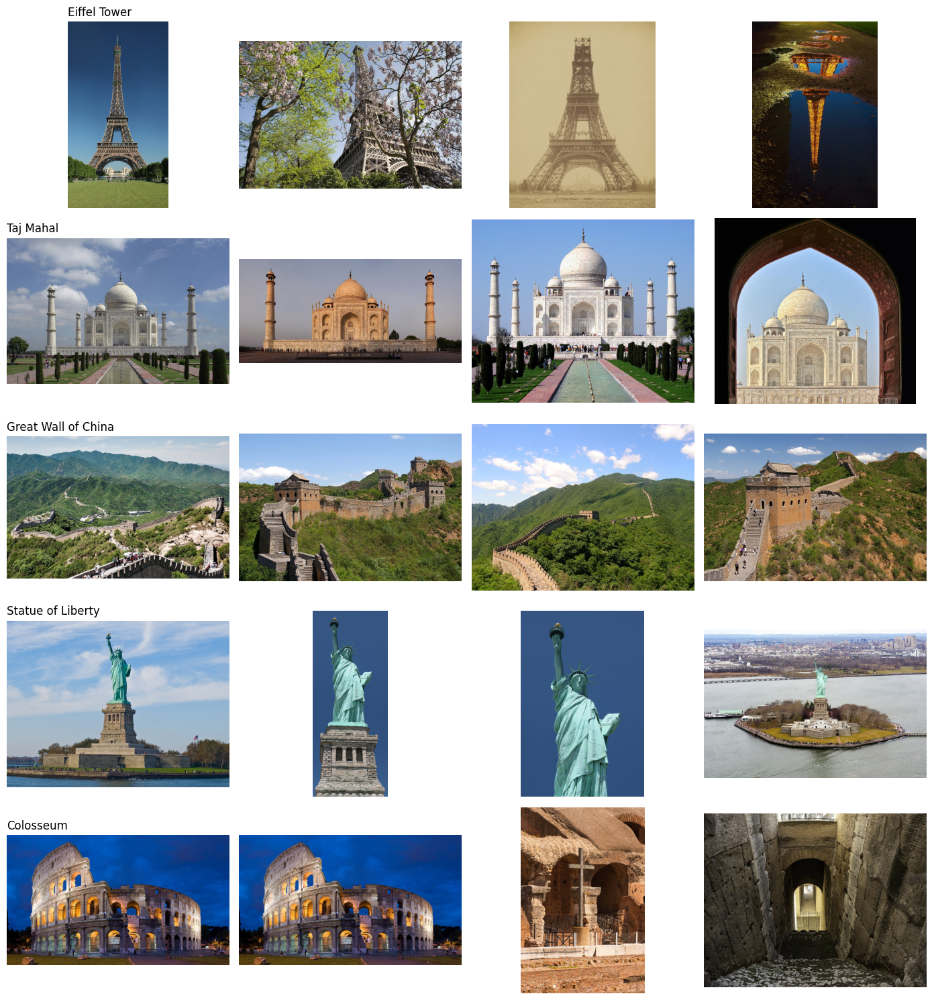

In [ ]:
fig, axes = plt.subplots(len(landmarks), 4, figsize=(14, 3 * len(landmarks)))
for i, name in enumerate(landmarks):
    for j in range(4):
        axes[i, j].axis("off")
        if j < len(references[name]):
            axes[i, j].imshow(rgb(references[name][j][1]))
            if j == 0:
                axes[i, j].set_title(name, loc="left")
plt.tight_layout()
plt.show()

## Task 2: SIFT feature extraction

In [ ]:
sift = cv2.SIFT_create()

def extract(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    return kp, des

features = {}
for name, items in references.items():
    features[name] = []
    for f, im in items:
        kp, des = extract(im)
        features[name].append({"file": f, "img": im, "kp": kp, "des": des})

summary = []
for name, refs in features.items():
    counts = [len(r["kp"]) for r in refs]
    summary.append([name, len(refs), sum(counts), int(np.mean(counts)) if counts else 0])
pd.DataFrame(summary, columns=["Landmark", "Reference images", "Total keypoints", "Avg keypoints per image"])

,Landmark,Reference images,Total keypoints,Avg keypoints per image
0,Eiffel Tower,8,21857,2732
1,Taj Mahal,8,13342,1667
2,Great Wall of China,8,27656,3457
3,Statue of Liberty,8,8497,1062
4,Colosseum,8,22430,2803


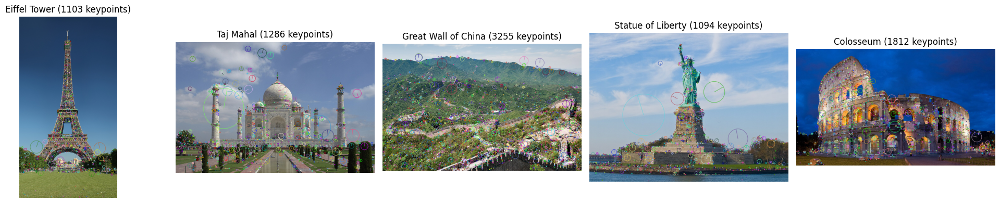

In [ ]:
fig, axes = plt.subplots(1, len(features), figsize=(4 * len(features), 4))
for ax, (name, refs) in zip(axes, features.items()):
    r = refs[0]
    out = cv2.drawKeypoints(r["img"], r["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(rgb(out))
    ax.set_title(name + " (" + str(len(r["kp"])) + " keypoints)")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
saved = {}
labels = []
for name, refs in features.items():
    for i, r in enumerate(refs):
        saved[name.replace(" ", "_") + "_" + str(i)] = r["des"]
        labels.append(name)
np.savez("landmark_descriptors.npz", **saved)
pd.DataFrame({"key": list(saved.keys()), "label": labels}).to_csv("descriptor_labels.csv", index=False)
print("saved", len(saved), "descriptor sets")

saved 40 descriptor sets


## Task 3: Query image processing

keypoints: 2447 | descriptor shape: (2447, 128)


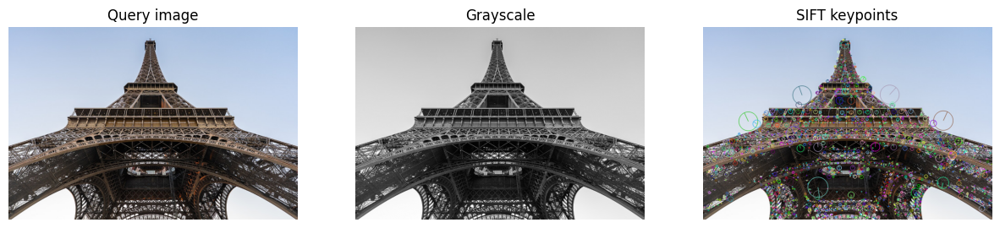

In [ ]:
query_landmark = "Eiffel Tower"
query_img = held_out[query_landmark][0][1]

q_gray = cv2.cvtColor(query_img, cv2.COLOR_BGR2GRAY)
q_kp, q_des = sift.detectAndCompute(q_gray, None)
print("keypoints:", len(q_kp), "| descriptor shape:", q_des.shape)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(rgb(query_img)); axes[0].set_title("Query image")
axes[1].imshow(q_gray, cmap="gray"); axes[1].set_title("Grayscale")
axes[2].imshow(rgb(cv2.drawKeypoints(query_img, q_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)))
axes[2].set_title("SIFT keypoints")
for ax in axes:
    ax.axis("off")
plt.show()

## Task 4 and 5: Matching, recognition and localization

In [ ]:
bf = cv2.BFMatcher(cv2.NORM_L2)

RATIO = 0.75
MIN_MATCHES = 15
MIN_INLIERS = 10
MIN_INLIER_RATIO = 0.25
MARGIN = 1.3

def ratio_matches(des_q, des_r):
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    pairs = bf.knnMatch(des_q, des_r, k=2)
    good = []
    for p in pairs:
        if len(p) == 2 and p[0].distance < RATIO * p[1].distance:
            good.append(p[0])
    return good

def localize(kp_q, ref, good):
    if len(good) < 4:
        return None, 0
    src = np.float32([ref["kp"][m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if H is None:
        return None, 0
    h, w = ref["img"].shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H)
    return poly, int(mask.sum())

def valid_polygon(poly, shape):
    pts = poly.reshape(-1, 2).astype(np.float32)
    if not np.all(np.isfinite(pts)):
        return False
    if not cv2.isContourConvex(pts.reshape(-1, 1, 2)):
        return False
    area = cv2.contourArea(pts)
    q_area = shape[0] * shape[1]
    return 0.02 * q_area < area < 5 * q_area

def analyse(img):
    t0 = time.time()
    kp_q, des_q = extract(img)
    ranking = []
    for name, refs in features.items():
        best_n, best_ref, best_good = 0, None, []
        for r in refs:
            good = ratio_matches(des_q, r["des"])
            if len(good) > best_n:
                best_n, best_ref, best_good = len(good), r, good
        ranking.append((name, best_n, best_ref, best_good))
    ranking.sort(key=lambda x: x[1], reverse=True)

    top_name, top_n, top_ref, top_good = ranking[0]
    second_n = ranking[1][1]
    poly, inliers = None, 0
    if top_ref is not None:
        poly, inliers = localize(kp_q, top_ref, top_good)
    poly_ok = poly is not None and valid_polygon(poly, img.shape)

    recognized = (top_n >= MIN_MATCHES and inliers >= MIN_INLIERS and inliers >= MIN_INLIER_RATIO * top_n
                  and poly_ok and top_n >= MARGIN * second_n)
    return {
        "kp": kp_q, "n_kp": len(kp_q), "ranking": ranking, "top_name": top_name, "top_n": top_n,
        "second_n": second_n, "ref": top_ref, "good": top_good, "poly": poly, "poly_ok": poly_ok,
        "inliers": inliers, "recognized": recognized, "time": time.time() - t0,
    }

In [ ]:
def show_result(img, res):
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    axes[0, 0].imshow(rgb(img))
    axes[0, 0].set_title("Query image")

    axes[0, 1].imshow(rgb(cv2.drawKeypoints(img, res["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)))
    axes[0, 1].set_title("Query keypoints (" + str(res["n_kp"]) + ")")

    if res["ref"] is not None and len(res["good"]) > 0:
        best = sorted(res["good"], key=lambda m: m.distance)[:50]
        drawn = cv2.drawMatches(img, res["kp"], res["ref"]["img"], res["ref"]["kp"], best, None,
                                matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        axes[1, 0].imshow(rgb(drawn))
    axes[1, 0].set_title("Matches with " + res["top_name"] + " (" + str(res["top_n"]) + " reliable)")

    loc = img.copy()
    if res["recognized"]:
        cv2.polylines(loc, [np.int32(res["poly"])], True, (0, 255, 0), 4)
        axes[1, 1].set_title("Localized region")
    else:
        axes[1, 1].set_title("No reliable geometric transformation")
    axes[1, 1].imshow(rgb(loc))

    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    table = pd.DataFrame([(n, c) for n, c, _, _ in res["ranking"]], columns=["Landmark", "Reliable matches"])
    print(table.to_string(index=False))
    print()
    if res["recognized"]:
        print("Recognized:", res["top_name"])
        print("Reliable matches:", res["top_n"], "| RANSAC inliers:", res["inliers"])
    else:
        print("Rejected - not recognized as any landmark in the database")
        print("Best candidate:", res["top_name"], "| reliable matches:", res["top_n"], "| RANSAC inliers:", res["inliers"])
        if not res["poly_ok"]:
            print("Geometric transformation unreliable, no polygon drawn")
    print("Processing time: %.2f s" % res["time"])

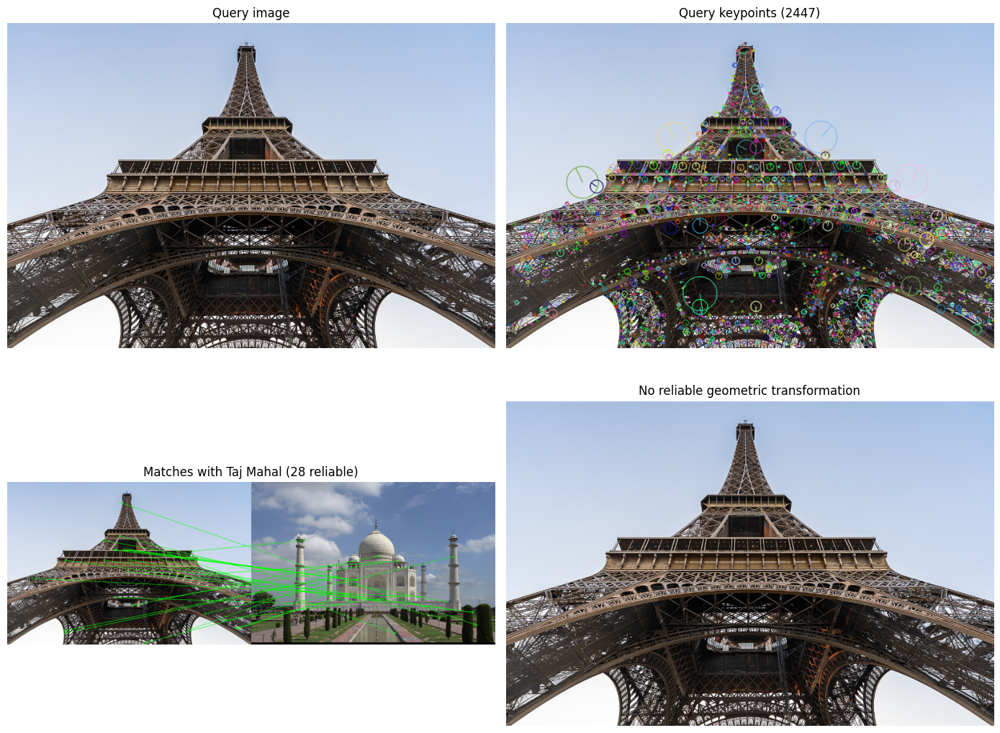

           Landmark  Reliable matches
          Taj Mahal                28
Great Wall of China                23
  Statue of Liberty                22
       Eiffel Tower                20
          Colosseum                18

Rejected - not recognized as any landmark in the database
Best candidate: Taj Mahal | reliable matches: 28 | RANSAC inliers: 6
Geometric transformation unreliable, no polygon drawn
Processing time: 8.67 s


In [ ]:
res = analyse(query_img)
show_result(query_img, res)

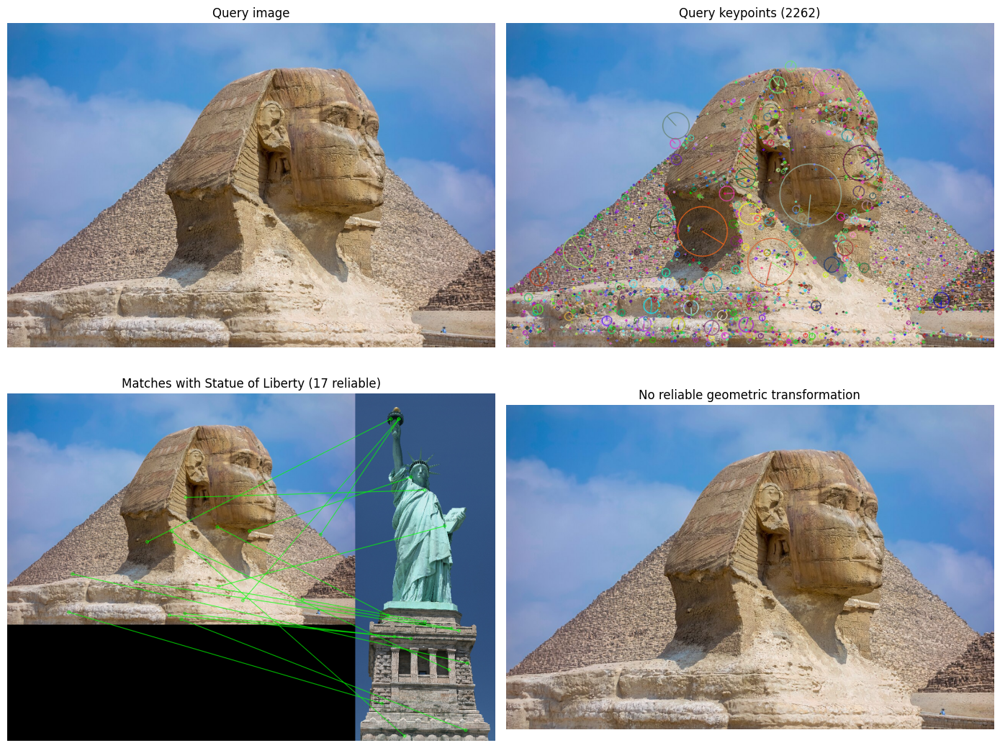

           Landmark  Reliable matches
  Statue of Liberty                17
       Eiffel Tower                15
          Taj Mahal                13
Great Wall of China                13
          Colosseum                11

Rejected - not recognized as any landmark in the database
Best candidate: Statue of Liberty | reliable matches: 17 | RANSAC inliers: 5
Geometric transformation unreliable, no polygon drawn
Processing time: 6.64 s


In [ ]:
res_unknown = analyse(unknown_imgs[0])
show_result(unknown_imgs[0], res_unknown)

## Task 6: Performance evaluation

In [ ]:
def rotate(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh))

def resize_half(img):
    return cv2.resize(img, None, fx=0.5, fy=0.5)

def darken(img):
    return cv2.convertScaleAbs(img, alpha=0.4, beta=0)

rows = []

def run_test(true_label, condition, img):
    res = analyse(img)
    predicted = res["top_name"] if res["recognized"] else "Unknown"
    if true_label == unknown_label:
        correct = not res["recognized"]
    else:
        correct = res["recognized"] and res["top_name"] == true_label
    rows.append({
        "True landmark": true_label, "Condition": condition, "Predicted": predicted,
        "Keypoints": res["n_kp"], "Reliable matches": res["top_n"], "Inliers": res["inliers"],
        "Decision": "Recognized" if res["recognized"] else "Rejected",
        "Correct": correct, "Time (s)": round(res["time"], 2),
    })

for name in landmarks:
    pool = held_out[name]
    if len(pool) == 0:
        continue
    base = pool[0][1]
    run_test(name, "Original", base)
    run_test(name, "Rotated (45 deg)", rotate(base, 45))
    run_test(name, "Resized (50%)", resize_half(base))
    run_test(name, "Reduced brightness", darken(base))
    if len(pool) > 1:
        run_test(name, "Different viewpoint", pool[1][1])

for img in unknown_imgs[:2]:
    run_test(unknown_label, "Landmark not in database", img)

results = pd.DataFrame(rows)
results.to_csv("sift_results.csv", index=False)
results

,True landmark,Condition,Predicted,Keypoints,Reliable matches,Inliers,Decision,Correct,Time (s)
0,Eiffel Tower,Original,Unknown,2447,28,6,Rejected,False,9.00
1,Eiffel Tower,Rotated (45 deg),Unknown,3211,37,6,Rejected,False,10.98
2,Eiffel Tower,Resized (50%),Unknown,679,10,4,Rejected,False,2.30
3,Eiffel Tower,Reduced brightness,Unknown,1546,17,7,Rejected,False,4.56
4,Eiffel Tower,Different viewpoint,Unknown,1692,19,5,Rejected,False,5.91
5,Taj Mahal,Original,Taj Mahal,1287,1099,1089,Recognized,True,4.64
6,Taj Mahal,Rotated (45 deg),Taj Mahal,1739,857,814,Recognized,True,5.26
7,Taj Mahal,Resized (50%),Taj Mahal,497,358,353,Recognized,True,1.46
8,Taj Mahal,Reduced brightness,Taj Mahal,317,294,293,Recognized,True,1.21
9,Taj Mahal,Different viewpoint,Taj Mahal,1124,968,960,Recognized,True,4.84


In [ ]:
summary = results.groupby("Condition").agg(
    Tests=("Correct", "count"),
    Correct=("Correct", "sum"),
    Avg_time=("Time (s)", "mean"),
)
summary["Accuracy (%)"] = (100 * summary["Correct"] / summary["Tests"]).round(1)
summary["Avg_time"] = summary["Avg_time"].round(2)
summary

,Tests,Correct,Avg_time,Accuracy (%)
Condition,,,,
Different viewpoint,5,2,6.68,40.0
Landmark not in database,2,2,5.18,100.0
Original,5,2,7.99,40.0
Reduced brightness,5,2,2.65,40.0
Resized (50%),5,1,2.54,20.0
Rotated (45 deg),5,1,10.29,20.0


In [ ]:
print("Overall accuracy: %.1f%%" % (100 * results["Correct"].mean()))

Overall accuracy: 37.0%


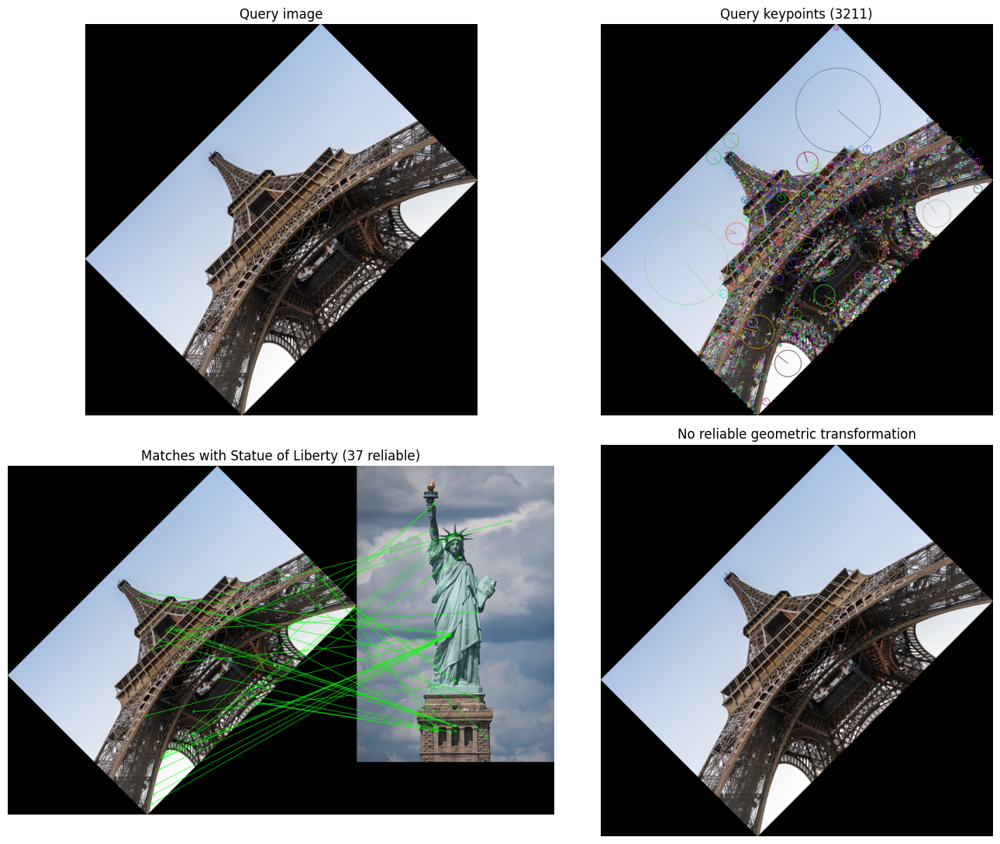

           Landmark  Reliable matches
  Statue of Liberty                37
       Eiffel Tower                34
          Taj Mahal                33
          Colosseum                33
Great Wall of China                29

Rejected - not recognized as any landmark in the database
Best candidate: Statue of Liberty | reliable matches: 37 | RANSAC inliers: 6
Geometric transformation unreliable, no polygon drawn
Processing time: 11.30 s


In [ ]:
rot_name = list(landmarks)[0]
rot_img = rotate(held_out[rot_name][0][1], 45)
show_result(rot_img, analyse(rot_img))